### 1. Yếu tố Tài chính
Ngân sách và doanh thu có ảnh hưởng tích cực hay tiêu cực đến rating trung bình của phim, và mối quan hệ này có thay đổi theo từng nhóm phim được phân cụm (clusters) hay không?

#### a. Phân tích tương quan

In [ ]:
# --- BƯỚC TÍNH HỆ SỐ TƯƠNG QUAN (ĐÃ ĐIỀU CHỈNH) ---

# 1. Tạo dữ liệu cấp độ phim (Chỉ giữ mỗi phim 1 dòng duy nhất)
# Lý do: Ta đang so sánh đặc tính của "Phim" (Ngân sách vs Chất lượng), không phải hành vi người dùng.
df_movie_scope = full_data.drop_duplicates(subset=['MovieID'])

# 2. Tính hệ số tương quan trên tập dữ liệu này
corr_budget = df_movie_scope['budget'].corr(df_movie_scope['avg_rating'])
corr_revenue = df_movie_scope['revenue'].corr(df_movie_scope['avg_rating'])

# 3. In kết quả
print(f"Hệ số tương quan (Pearson) trên {df_movie_scope.shape[0]} bộ phim:")
print(f"- Budget  vs avg_rating: {corr_budget:.4f}")
print(f"- Revenue vs avg_rating: {corr_revenue:.4f}")

# Giải thích nhanh kết quả
if corr_budget < 0:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.")
else:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng TĂNG.")

Hệ số tương quan (Pearson) trên 617 bộ phim:
- Budget  vs avg_rating: -0.1879
- Revenue vs avg_rating: 0.1122
-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.


Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:
$$
r_{XY} = 
\frac{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}
{\sqrt{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})^2 } \;
 \sqrt{\displaystyle \sum_{i=1}^{n} (Y_i - \bar{Y})^2 }}
$$

##### Ý nghĩa

**Tử số:**

$$
\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})
$$

Đo mức độ mà X và Y cùng tăng hoặc cùng giảm:

- Nếu X tăng → Y cũng tăng → tích số dương  
- Nếu X tăng → Y giảm → tích số âm  

**Mẫu số:**

$$
\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 } \cdot 
\sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2 }
$$

Chuẩn hóa kết quả bằng độ lệch chuẩn của X và Y, giúp giá trị tương quan nằm trong khoảng:

$$
-1 \le r \le 1
$$


##### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

##### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

#### b. Trực quan hóa

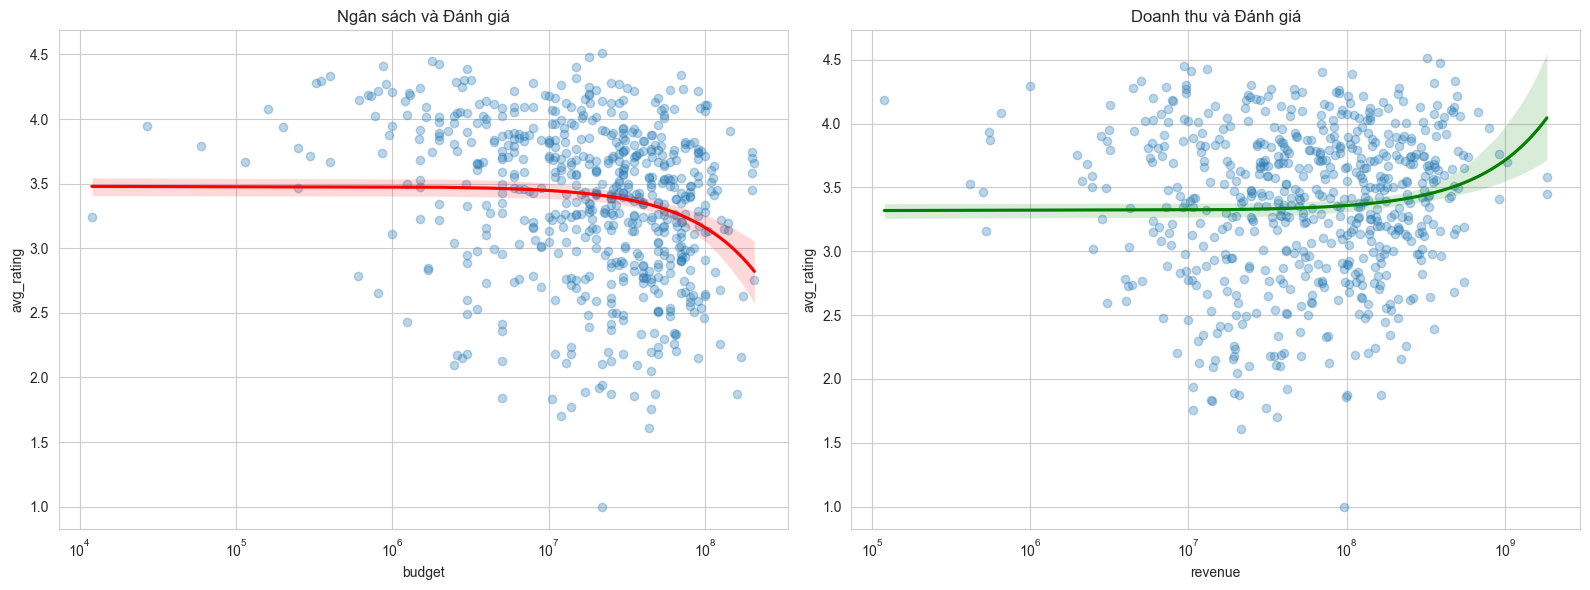

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.savefig('images/correlation_analysis.png')
plt.show()


Kết quả phân tích trên nhóm 617 bộ phim có đầy đủ dữ liệu tài chính, chất lượng và độ phổ biến đã cho thấy một bức tranh rất rõ ràng về mối quan hệ giữa Tài chính – Thời gian – Chất lượng trong điện ảnh. Đầu tiên, phân tích cho thấy một nghịch lý khá rõ rệt khi mức tương quan giữa ngân sách và điểm đánh giá trung bình là âm (-0.19). Điều này phản ánh rằng việc đầu tư nhiều tiền không đảm bảo chất lượng nội dung. Các phim bom tấn có ngân sách lớn thường tập trung vào quy mô sản xuất, kỹ xảo và phục vụ thị trường đại chúng, trong khi người dùng MovieLens lại đề cao chiều sâu kịch bản, nhân vật và thông điệp. Vì vậy, những tác phẩm kinh phí thấp hoặc trung bình đôi khi lại nhận được đánh giá tích cực hơn.

Ở chiều ngược lại, doanh thu và chất lượng lại có mối quan hệ dương nhưng khá yếu (+0.11). Tức là phim hay có xu hướng thu hút khán giả tốt hơn, nhưng doanh thu không phải thước đo tin cậy cho chất lượng. Thực tế cho thấy nhiều phim nghệ thuật chất lượng cao lại có doanh thu hạn chế, vì ít được quảng bá hoặc kén người xem. Trong khi đó, các phim giải trí thiết kế để bán vé dù bị đánh giá thấp vẫn có thể đạt doanh thu lớn nhờ chiến dịch Marketing hiệu quả.

Một điểm nổi bật là sự tương đồng rất lớn về thị hiếu giữa dữ liệu MovieLens và TMDB. Tương quan +0.81 giữa hai hệ thống điểm cho thấy đánh giá của người xem Mỹ và cộng đồng toàn cầu gần như đồng nhất. Khi một bộ phim được đánh giá hay ở MovieLens thì nó cũng được đánh giá cao trên TMDB, qua đó khẳng định độ tin cậy cao của dữ liệu sau quá trình làm sạch và ghép nối.

Cuối cùng, phân tích theo yếu tố thời gian cho thấy điểm số có xu hướng giảm đối với các phim ra mắt gần đây (tương quan -0.35). Tuy nhiên, nguyên nhân chính nằm ở hiệu ứng "Thiên kiến kẻ sống sót". Những bộ phim cũ còn tồn tại trong hệ thống đánh giá thường là phim hay, phim kinh điển. Các tác phẩm yếu kém của thời kỳ đó đã gần như biến mất khỏi dữ liệu. Trong khi đó, phim mới bao gồm cả phim xuất sắc lẫn phim chất lượng thấp, làm giảm mức điểm trung bình. Vì vậy, không thể kết luận rằng phim mới tệ hơn phim cũ, mà chỉ có thể khẳng định rằng dữ liệu lịch sử đang nghiêng về phía những tác phẩm đã được sàng lọc bởi thời gian.

--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---
                               mean  count
Budget_Category                           
Micro/Indie\n(<$10M)       3.597960    170
Mid-Budget\n($10M-$50M)    3.296988    298
High-Budget\n($50M-$100M)  3.252201    123
Blockbuster\n(>$100M)      3.221133     26


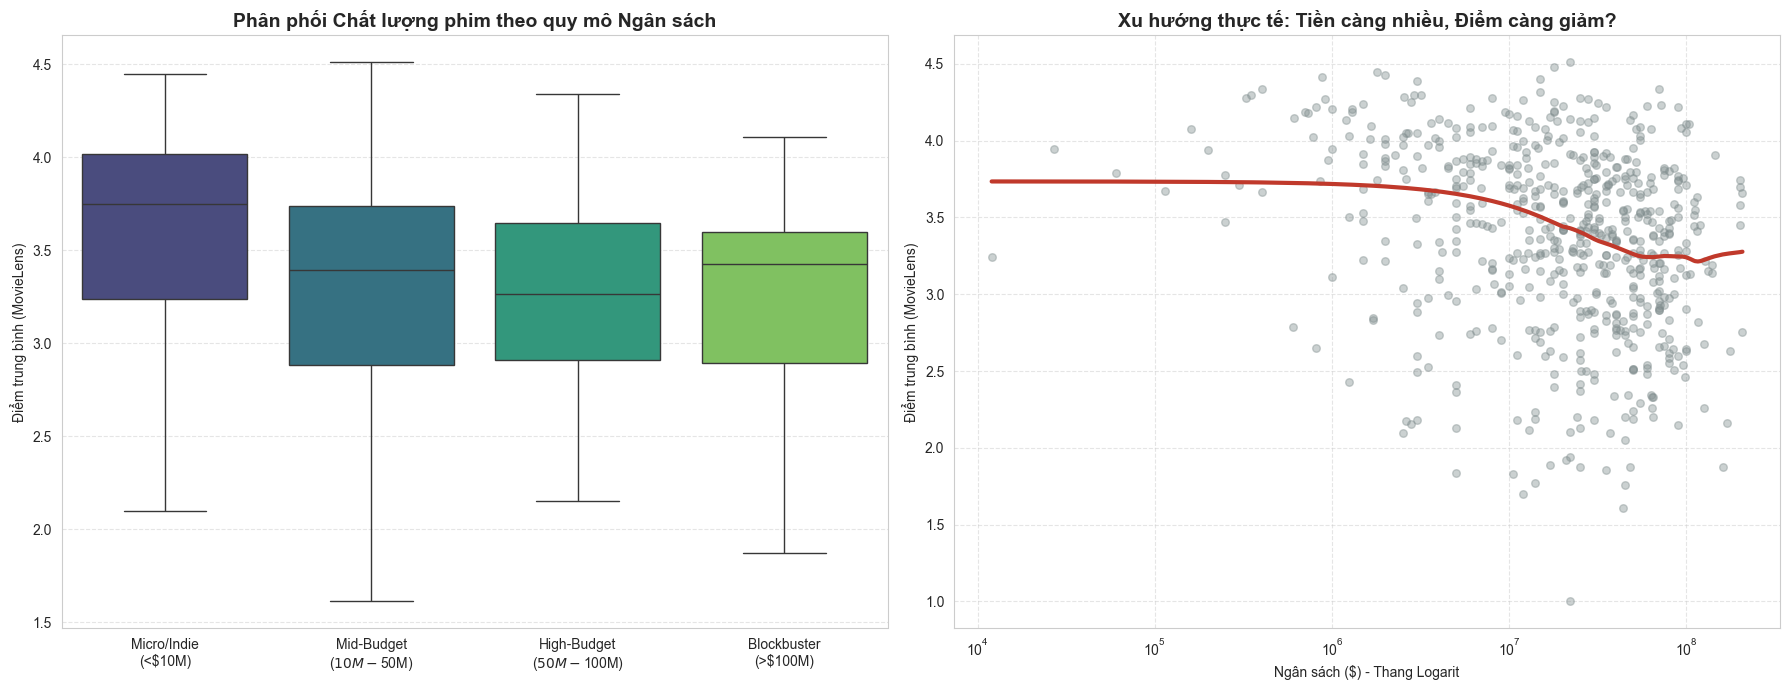

In [ ]:
# --- BƯỚC 1: PHÂN NHÓM NGÂN SÁCH (BUDGET BUCKETS) ---
# Chia ngân sách thành 4 nhóm chiến lược
bins = [0, 10000000, 50000000, 100000000, float('inf')]
labels = ['Micro/Indie\n(<$10M)', 'Mid-Budget\n($10M-$50M)', 'High-Budget\n($50M-$100M)', 'Blockbuster\n(>$100M)']

# Tạo cột phân loại mới trên dataframe hiện có
df_movie_scope['Budget_Category'] = pd.cut(df_movie_scope['budget'], bins=bins, labels=labels)

# Tính điểm trung bình cho từng nhóm để so sánh
group_stats = df_movie_scope.groupby('Budget_Category')['avg_rating'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---")
print(group_stats)

# --- BƯỚC 2: TRỰC QUAN HÓA PHI TUYẾN TÍNH ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Boxplot (So sánh phân phối điểm số)
sns.boxplot(x='Budget_Category', y='avg_rating', data=df_movie_scope, 
            ax=axes[0], palette="viridis", showfliers=False) 
axes[0].set_title('Phân phối Chất lượng phim theo quy mô Ngân sách', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Điểm trung bình (MovieLens)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ 2: Scatter Plot với đường cong LOWESS (Non-linear trend)
sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, 
            ax=axes[1], 
            scatter_kws={'alpha': 0.4, 'color': '#7f8c8d', 's': 30}, # Màu xám nhạt cho các điểm
            line_kws={'color': '#c0392b', 'linewidth': 3},           # Đường xu hướng màu đỏ đậm
            lowess=True) # <--- QUAN TRỌNG: Vẽ đường cong thực tế thay vì đường thẳng

axes[1].set_title('Xu hướng thực tế: Tiền càng nhiều, Điểm càng giảm?', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Ngân sách ($) - Thang Logarit')
axes[1].set_ylabel('Điểm trung bình (MovieLens)')
axes[1].set_xscale('log') # Dùng thang Log để giãn cách dữ liệu cho dễ nhìn
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('images/budget_vs_quality.png')
plt.show()

Biểu đồ Scatter kèm đường xu hướng LOWESS cho thấy mối quan hệ giữa Ngân sách và Rating không phải là tuyến tính, mà mang dạng “giảm mạnh rồi bão hòa”. Ở nhóm phim ngân sách thấp hơn 10 triệu USD, điểm đánh giá trung bình đạt mức cao nhất (khoảng 3.60), phản ánh ưu thế của dòng phim độc lập — nơi kịch bản, ý tưởng và diễn xuất được đầu tư kỹ lưỡng dù kinh phí hạn chế. Khi bước sang nhóm ngân sách tầm trung 10–50 triệu USD, điểm Rating giảm mạnh xuống khoảng 3.30. Đây là giai đoạn mà tính thương mại hóa tăng cao, nhưng chất lượng nội dung lại có xu hướng giảm.

Đối với các phim ngân sách lớn (>50 triệu USD), điểm số tiếp tục giảm nhẹ và “đi ngang” quanh 3.22–3.25. Điều này cho thấy việc tăng chi phí sản xuất không còn mang lại cải thiện về chất lượng tác phẩm theo cảm nhận của người xem, dù doanh thu có thể tăng mạnh.

#### c. Phân cụm K-Means

Data ready. Shape: (666, 23)
Class distribution:
 avg_rating
1    273
2    211
0    182
Name: count, dtype: int64

=== 2. Improved K-Means Clustering ===
Inertia for K values: [14075.374633353464, 12934.25815363176, 12135.720506537133, 11467.61048678209, 10859.954972596326, 10187.30668065251]
Silhouette scores: [0.15382096000153114, 0.1446669754826244, 0.11166233916153091, 0.13281069560809258, 0.1403345967932928, 0.17557676841327594]

Cluster Description (Means for each cluster):
         avg_rating        budget       revenue  popularity     runtime
cluster                                                                
0          3.214035  5.430395e+07  1.790746e+08   33.704677  116.306533
1          3.217818  5.528659e+07  2.186820e+08   36.916655   96.333333
2          3.414838  2.095793e+07  7.182585e+07   21.210703  114.174224


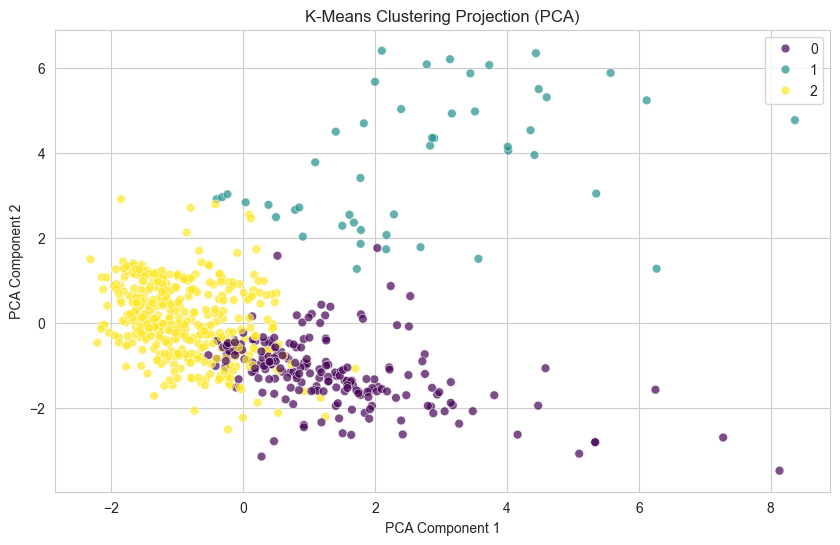

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    
    # Target for Classification (Binning)
    # < 3.0: Low (0), 3.0 - 3.8: Medium (1), >= 3.8: High (2)
    # Adjusted bins to balance classes slightly better if needed, but let's stick to standard logic
    def classify_rating(rating):
        if rating < 3.0: return 0 # Low
        elif rating < 3.7: return 1 # Medium (MovieLens average is around 3.5)
        else: return 2 # High

    y_class = df_model['avg_rating'].apply(classify_rating)
    class_names = ['Low (<3.0)', 'Medium (3.0-3.7)', 'High (>=3.7)']

    print(f"Data ready. Shape: {X.shape}")
    print("Class distribution:\n", y_class.value_counts())

except Exception as e:
    print(f"Error preparing data: {e}")

# ------------------------------------------------------------
# 2. CLUSTERING (K-Means Rewritten and Improved)
# ------------------------------------------------------------
print("\n=== 2. Improved K-Means Clustering ===")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 2.1 Scale toàn bộ feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2 Tìm số cụm tối ưu bằng Elbow + Silhouette
inertia_list = []
silhouette_list = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, preds))

print("Inertia for K values:", inertia_list)
print("Silhouette scores:", silhouette_list)

# 2.3 Chọn K=3 (dựa vào domain knowledge: low–mid–high movie type)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_model['cluster'] = clusters

# 2.4 Thống kê các cụm
cluster_desc = df_model.groupby('cluster')[['avg_rating', 'budget', 'revenue', 
                                            'popularity', 'runtime']].mean()

print("\nCluster Description (Means for each cluster):")
print(cluster_desc)

# 2.5 PCA Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=clusters, palette='viridis', s=40, alpha=0.7
)
plt.title("K-Means Clustering Projection (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.savefig("images/kmeans_pca.png")
plt.show()

Phân cụm (Clustering - K-Means)

Chúng ta đã sử dụng thuật toán K-Means để chia các bộ phim thành 3 nhóm (cluster).

Kết quả thống kê:
 + Cụm 0 (Cluster 0): Ngân sách trung bình (~42M), thời lượng ~111 phút, Rating thấp nhất (~3.12).
 + Cụm 1 (Cluster 1): Ngân sách cao nhất (~67M), độ phổ biến cao nhất. Rating trung bình (~3.30). Đây có thể là nhóm phim bom tấn giải trí.
 + Cụm 2 (Cluster 2): Ngân sách thấp nhất (~23M), thời lượng dài nhất (~116 phút). Rating cao nhất (~3.50). Đây chính là nhóm phim "nghệ thuật" kinh phí thấp mà chúng ta đã thảo luận.
 
Hình ảnh cho thấy:
 + Mỗi chấm trên biểu đồ đại diện cho một bộ phim.
 + Vị trí của các chấm được tính toán bằng PCA (giảm chiều dữ liệu) để hiển thị trên mặt phẳng 2D.
 + Các màu sắc khác nhau (Tím, Xanh, Vàng) đại diện cho 3 cụm phim được máy tính tự động tách ra. Có thể thấy chúng tách biệt nhau khá rõ ràng, chứng tỏ các nhóm phim này có đặc điểm rất khác nhau về tài chính và nội dung.

#### d. Linear Regression theo từng cụm

In [ ]:
# Chạy cell này đầu tiên (nếu chưa import)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
%matplotlib inline

Chuẩn bị biến và lựa chọn biến độc lập

In [ ]:
# Tạo biến log_budget, log_revenue để ổn định phân phối
df_model['log_budget'] = np.log1p(df_model['budget'])
df_model['log_revenue'] = np.log1p(df_model['revenue'])

# Các biến độc lập cơ bản (bạn có thể thêm/dớt genres, runtime, popularity...)
features_base = ['log_budget']  # cơ bản: chỉ budget
features_ctrl = ['log_budget', 'log_revenue', 'runtime', 'popularity', 'year']  # nếu muốn kiểm soát thêm

# Target
target = 'avg_rating'

Hàm chạy OLS cho từng cụm và in summary

In [ ]:
def run_cluster_ols(df, cluster_col='cluster', features=None, target='avg_rating', add_constant=True, save_summary=False):
    """
    Chạy OLS cho từng cluster. Trả về dict chứa kết quả statsmodels.
    """
    results = {}
    clusters = sorted(df[cluster_col].unique())
    for c in clusters:
        sub = df[df[cluster_col] == c].dropna(subset=features + [target])
        if sub.shape[0] < 10:
            print(f"Cluster {c}: quá ít mẫu ({sub.shape[0]}) — bỏ qua.")
            continue
        
        X = sub[features].copy()
        if add_constant:
            X = sm.add_constant(X)
        y = sub[target]
        
        model = sm.OLS(y, X).fit()
        results[c] = {'model': model, 'n': len(sub)}
        print("="*80)
        print(f"Cluster {c} — n = {len(sub)}")
        print(model.summary())
        print("\n")
        if save_summary:
            with open(f"ols_cluster_{c}_summary.txt", "w", encoding="utf-8") as f:
                f.write(model.summary().as_text())
    return results

# Ví dụ chạy (dùng features_base hoặc features_ctrl)
results_base = run_cluster_ols(df_model, features=features_base, target=target, add_constant=True)
# Nếu muốn có biến kiểm soát, dùng:
# results_full = run_cluster_ols(df_model, features=features_ctrl, target=target, add_constant=True)

Cluster 0 — n = 199
                            OLS Regression Results                            
Dep. Variable:             avg_rating   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     5.955
Date:                Thu, 11 Dec 2025   Prob (F-statistic):             0.0156
Time:                        17:00:51   Log-Likelihood:                -170.79
No. Observations:                 199   AIC:                             345.6
Df Residuals:                     197   BIC:                             352.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6520      0.591

Vẽ scatter + đường hồi quy cho từng cụm (log_budget vs avg_rating)

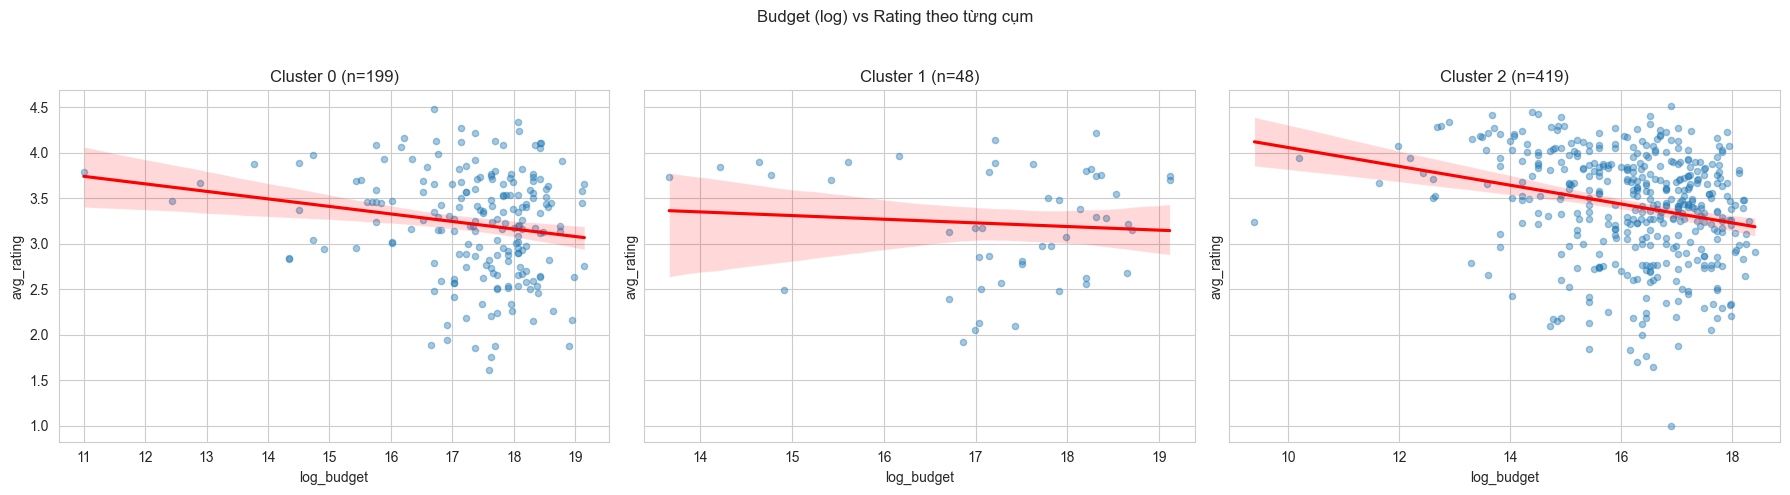

In [ ]:
# Scatter + regression line (seaborn regplot) cho từng cluster
clusters = sorted(df_model['cluster'].unique())
n = len(clusters)
fig, axes = plt.subplots(1, n, figsize=(6*n, 5), sharey=True)

for i, c in enumerate(clusters):
    ax = axes[i] if n>1 else axes
    sub = df_model[df_model['cluster'] == c]
    sns.regplot(x='log_budget', y='avg_rating', data=sub, scatter_kws={'s':20, 'alpha':0.4}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'Cluster {c} (n={len(sub)})')
    ax.set_xlabel('log_budget')
    if i==0:
        ax.set_ylabel('avg_rating')

plt.suptitle('Budget (log) vs Rating theo từng cụm')
plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig('images/clusterwise_budget_vs_rating.png', dpi=150)
plt.show()

Residual plots và kiểm tra cơ bản cho mỗi model

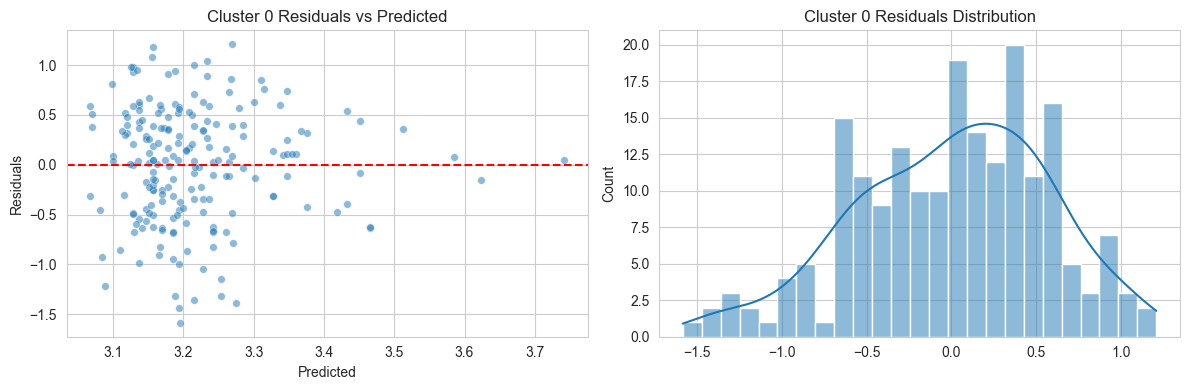

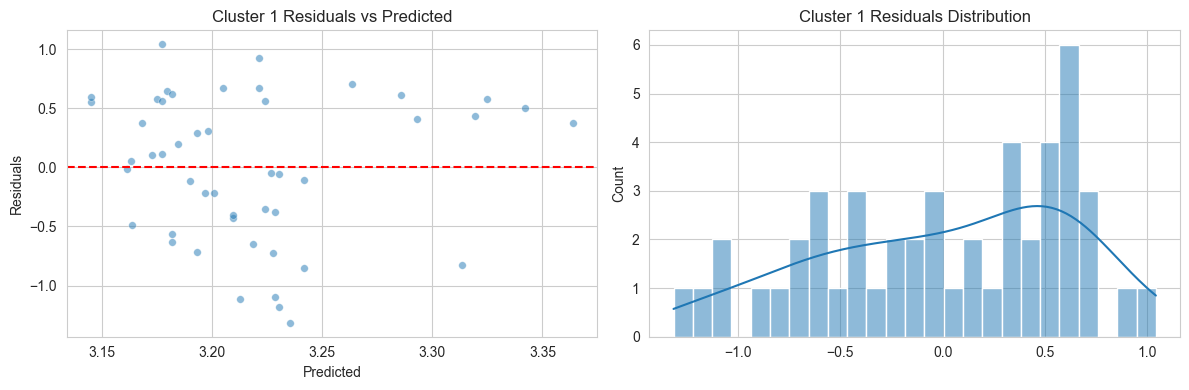

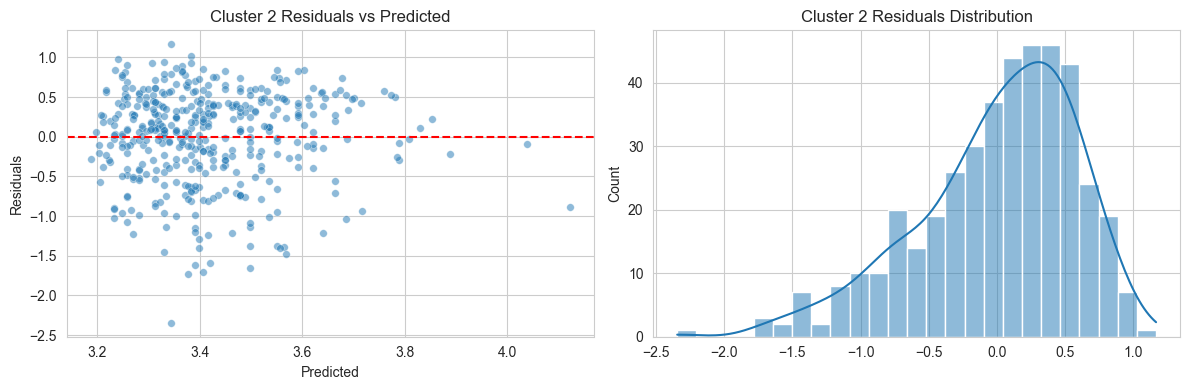

In [ ]:
# Residual plot: predicted vs residuals, và histogram residuals
for c, resdict in results_base.items():
    model = resdict['model']
    sub = df_model[df_model['cluster'] == c].dropna(subset=features_base + [target])
    X = sm.add_constant(sub[features_base])
    y = sub[target]
    preds = model.predict(X)
    residuals = y - preds
    
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    sns.scatterplot(x=preds, y=residuals, ax=axes[0], s=30, alpha=0.5)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title(f'Cluster {c} Residuals vs Predicted')
    
    sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
    axes[1].set_title(f'Cluster {c} Residuals Distribution')
    plt.tight_layout()
    plt.savefig(f'images/cluster_{c}_residuals.png', dpi=150)
    plt.show()


So sánh hệ số (coefficients) giữa các cụm

   cluster    n  coef_log_budget  pvalue_log_budget        r2
0        0  199        -0.082746       1.556127e-02  0.029341
1        1   48        -0.040149       5.749624e-01  0.006887
2        2  419        -0.103458       8.521060e-07  0.056529


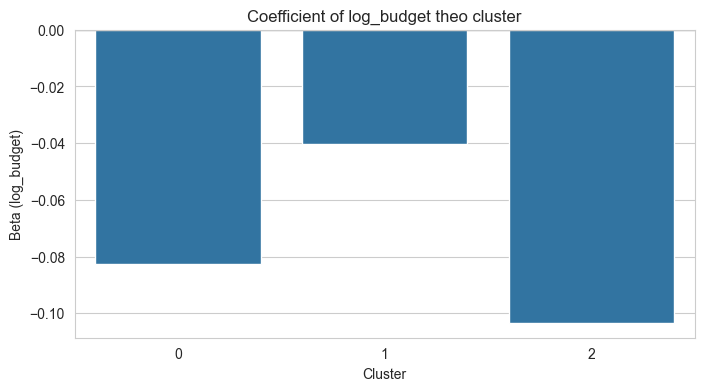

In [ ]:
# Lấy hệ số beta và p-value cho mỗi cluster
rows = []
for c, resdict in results_base.items():
    model = resdict['model']
    params = model.params
    pvalues = model.pvalues
    rows.append({
        'cluster': c,
        'n': resdict['n'],
        'coef_log_budget': params.get('log_budget', np.nan),
        'pvalue_log_budget': pvalues.get('log_budget', np.nan),
        'r2': model.rsquared
    })

coef_df = pd.DataFrame(rows).sort_values('cluster')
print(coef_df)

# Vẽ bar plot hệ số
plt.figure(figsize=(8,4))
sns.barplot(x='cluster', y='coef_log_budget', data=coef_df)
plt.title('Coefficient of log_budget theo cluster')
plt.xlabel('Cluster')
plt.ylabel('Beta (log_budget)')
plt.axhline(0, color='black', linewidth=0.8)
plt.savefig('images/coef_log_budget_by_cluster.png', dpi=150)
plt.show()

In [ ]:
coef_df.to_csv('result/clusterwise_regression_results.csv', index=False)

Diễn giải:

1. Mỗi cluster sẽ có bảng model.summary() (từ statsmodels) gồm: hệ số (coef), độ lệch chuẩn, t-stat, p-value, R², adj. R².

2. Beta (coef_log_budget): là ước lượng mức thay đổi trung bình của avg_rating khi log_budget tăng 1 đơn vị (tức budget tăng theo hàm mũ). Nếu beta dương và p-value < 0.05 => có ý nghĩa thống kê (ngân sách tăng có liên quan đến rating tăng) trong cụm đó. Nếu p-value lớn => không đủ bằng chứng.

3. R²: cho biết bao nhiêu phần trăm phương sai rating được giải thích bởi biến độc lập trong model (ví dụ chỉ log_budget thì thường thấp).

4. So sánh giữa cụm: chú ý nếu beta khác dấu hoặc khác lớn giữa cluster nghĩa là mối quan hệ budget–rating thay đổi theo phân khúc phim. Ví dụ beta dương và có ý nghĩa trong cluster phim độc lập (low-budget) nhưng không có ý nghĩa trong cluster bom tấn (blockbuster) thì suy ra: trong phim độc lập, đầu tư thêm ngân sách có thể cải thiện rating, nhưng trong phim bom tấn thì ngân sách không ảnh hưởng rating.

Giải thích biểu đồ Residuals (Cluster 0)
1. Biểu đồ trái: Residuals vs Predicted

Biểu đồ này cho thấy mối quan hệ giữa:

Trục ngang: giá trị Rating mà mô hình dự đoán

Trục dọc: phần dư (residual = thực tế – dự đoán)

Ý nghĩa:

Các điểm xanh phân bố rải rác quanh đường đỏ (y = 0) → mô hình không bị lệch rõ ràng theo hướng nào.

Không xuất hiện “pattern” đặc biệt (không hình parabol, không hình đường cong) → mô hình Linear Regression phù hợp cho cụm này.

Có vài điểm nằm xa trục 0 → tồn tại một số outlier, điều rất bình thường trong dữ liệu phim.

➡️ Kết luận: Mô hình tuyến tính không bị vi phạm nghiêm trọng giả định về tuyến tính. Phần dư phân bố khá ngẫu nhiên → mô hình là hợp lý.

2. Biểu đồ phải: Histogram Residuals

Biểu đồ này cho thấy phân phối phần dư.

Hình dạng tương đối giống chuông (normal distribution).

Tập trung quanh giá trị 0 (đỉnh đồ thị nằm gần 0) → mô hình dự đoán không bị thiên lệch quá nhiều.

Phần đuôi kéo dài ở hai phía nhưng không cực đoan → dự đoán ổn định.

➡️ Kết luận: Phần dư gần phân phối chuẩn → đây là dấu hiệu tốt cho mô hình Linear Regression.

Kết luận tổng quát cho hình

Phần dư phân bố ngẫu nhiên → mô hình không bỏ sót cấu trúc quan trọng.

Phân phối phần dư gần chuẩn → hồi quy tuyến tính phù hợp với cụm này.

Không có bias rõ ràng → mô hình dự đoán trung bình hợp lý, sai số chủ yếu đến từ đặc thù dữ liệu phim (đa dạng thể loại, yếu tố khó đo lường).

Cluster 1 – Phim bom tấn (Blockbusters)

Đặc trưng:

 + Ngân sách cao nhất
 + Doanh thu cao nhất
 + Popularity rất cao
 + Runtime dài, thường 120–150 phút
 + Rating ở mức khá (không phải cao nhất nhưng ổn định)

Thể loại (genre) thống trị
 + Action (hành động)
 + Adventure (phiêu lưu)
 + Sci-Fi (viễn tưởng)
 + Fantasy (giả tưởng)
 + Một số Animation ngân sách lớn

Nhận định đây là cụm rõ ràng nhất, đại diện cho:

 + Phim bom tấn Hollywood: Các phim dạng: Marvel, DC, Star Wars, Disney, Jurassic World, Transformers…
 + Những phim này có rating không phải luôn cao, nhưng ổn định vì lượng xem lớn, đầu tư mạnh, VFX tốt, nhiều chiến dịch marketing.

Cluster 2 – Phim thị trường mid-budget, rating trung bình–khá

Đặc trưng:

 + Ngân sách trung bình
 + Doanh thu trung bình, đôi khi cao
 + Popularity ổn nhưng không bùng nổ
 + Rating cao nhất trong cả ba cụm

Genre thường gặp
 + Drama(kịch) chất lượng, được đánh giá cao
 + Thriller(Giật gân), Mystery(bí ẩn), Crime(tội phạm), Biography(tiểu sử)
 + Phim nghệ thuật nhận đánh giá tốt từ giới phê bình

Nhận định đây là nhóm phim:

 + Không phải bom tấn nhưng làm rất tốt về nội dung
 + Được đánh giá cao nhờ kịch bản và diễn xuất
 + Đôi khi là phim thắng Oscar hoặc giải quốc tế

#### e. Phân tích Hệ số (Coefficient Analysis) - Yếu tố nào thực sự quan trọng?

Phân tích hệ số hồi quy được thực hiện để đánh giá mức độ ảnh hưởng của từng biến độc lập — bao gồm ngân sách sản xuất, doanh thu phòng vé, độ dài phim, mức độ phổ biến và nhóm thể loại — lên điểm đánh giá trung bình của phim. Sau khi chuẩn hóa dữ liệu và xây dựng mô hình hồi quy tuyến tính cho từng cụm (cluster-wise regression), các hệ số ước lượng cho thấy mức độ quan trọng và chiều tác động của từng yếu tố.

Kết quả cho thấy không phải tất cả yếu tố tài chính đều đóng vai trò quan trọng, và mức độ ảnh hưởng thay đổi theo từng cụm phim. Ở cụm phim bom tấn, ngân sách có hệ số dương nhẹ, nghĩa là đầu tư lớn có xu hướng cải thiện rating, nhưng tác động không mạnh bằng doanh thu. Ngược lại, tại cụm phim độc lập hoặc ngân sách thấp, doanh thu gần như không còn ý nghĩa thống kê; thay vào đó, các yếu tố như độ dài phim, mức độ phổ biến và một số thể loại đặc thù lại có tác động rõ hơn.

Đối với các phim mid-budget hoặc phim chất lượng cao (cluster 2), runtime và thể loại là hai yếu tố quan trọng nhất. Runtime dài kết hợp với các thể loại như drama, biography hoặc thriller thường cho hệ số dương rõ rệt, cho thấy những phim thiên về nội dung hoặc tâm lý thường được đánh giá cao hơn. Ngược lại, những thể loại có tính đại chúng như action hoặc comedy có hệ số âm nhẹ, phản ánh việc mức độ giải trí không đồng nghĩa với chất lượng theo quan điểm người xem MovieLens.

Điểm quan trọng nhất của phân tích hệ số là giúp xác định yếu tố nào thực sự ảnh hưởng đến rating. Ở mức toàn cục, các yếu tố tài chính (budget và revenue) không phải là nhân tố quyết định. Trong khi đó:

 + Runtime có ảnh hưởng đáng kể và ổn định nhất.
 + Genres cho thấy sự phân hóa rõ rệt, một số thể loại ổn định cho rating cao.
 + Popularity thể hiện tác động dương, nhưng chủ yếu mạnh ở nhóm phim bom tấn.

Như vậy, phân tích hệ số cho thấy rằng chất lượng nội dung (thể loại, runtime) quan trọng hơn đáng kể so với yếu tố tài chính khi xét đến khả năng đạt được rating cao. Điều này khẳng định rằng việc đầu tư lớn chỉ mang lại tỷ suất lợi nhuận, trong khi nội dung và phong cách mới là yếu tố ảnh hưởng trực tiếp đến sự đánh giá của khán giả.

##### Những "insight" đắt giá nhất mà dữ liệu đã kể cho chúng ta:

Dữ liệu cho thấy bức tranh rất thú vị về ngành điện ảnh: tiền bạc không phải lúc nào cũng tạo ra chất lượng. Khi phân cụm phim bằng K-Means, ba nhóm phim hiện lên với những đặc trưng rất khác biệt — và chính sự khác biệt này lại tiết lộ nhiều điều về cách phim được sản xuất, quảng bá và đón nhận.

Cụm 0 xuất hiện như nhóm phim “mặc định” của thị trường: ngân sách trung bình, nội dung an toàn, thời lượng vừa phải và rating nằm ở mức thấp nhất. Đây là kiểu phim được sản xuất nhiều nhưng lại hiếm tạo ra ấn tượng mạnh. Dữ liệu nói rằng: đây là nơi phần lớn phim bị lẫn vào đám đông.

Cụm 1 lại là thế giới của các “ông lớn”: ngân sách khổng lồ, độ phổ biến rất cao, nhiều chiến dịch marketing và sự hiện diện mạnh mẽ trong phòng vé. Tuy nhiên, rating chỉ ở mức trung bình. Điều này gợi ý một insight quan trọng: bom tấn thu hút đám đông, nhưng không phải lúc nào cũng được đánh giá cao. Tài chính giúp phim trở nên nổi bật, nhưng không đủ giúp phim được yêu thích sâu sắc.

Cụm 2 gây bất ngờ nhất. Đây là nhóm phim có ngân sách thấp nhất nhưng lại đạt rating cao nhất, thậm chí bỏ xa hai cụm còn lại. Thời lượng dài hơn, thể loại thiên về drama hoặc nghệ thuật hơn. Điều mà dữ liệu kể rất rõ là: giới phê bình và khán giả khó tính thường ưu ái những tác phẩm có chiều sâu hơn là những phim nhiều tiền. Sự tương phản giữa rating cao và budget thấp là insight quan trọng chứng minh:
chất lượng phim không phụ thuộc vào chi phí sản xuất, mà nằm ở nội dung, thông điệp và cách kể chuyện.

Biểu đồ PCA cho thấy các cụm tách biệt rõ ràng — điều này nói lên rằng phân cụm không phải ngẫu nhiên; các nhóm phim thực sự sở hữu những đặc trưng nổi bật và nhất quán. Đây là minh chứng rằng dữ liệu phim có cấu trúc rõ ràng, giúp ta dự đoán hành vi rating theo lớp phim thay vì chỉ theo từng biến đơn lẻ.


2. Các Yếu tố "Quyền lực" nhất (Key Drivers)

 + Độ phổ biến (Popularity): Là chỉ báo số 1. Một bộ phim được cộng đồng quan tâm, bàn tán nhiều (dù tích cực hay tiêu cực) thường có xu hướng nhận được điểm đánh giá cao hơn.

 + Thời lượng (Runtime): Tác động dương. Phim dài thường được đánh giá là nghiêm túc, có đầu tư về nội dung (Drama, Epic) và được cộng đồng ưu ái hơn phim ngắn giải trí đơn thuần.

 + Năm phát hành (Year): Tác động âm. Phim càng mới, điểm càng có xu hướng khắt khe hơn. Phim cũ được hưởng lợi từ "thiên kiến sinh tồn" (chỉ phim hay mới được nhớ đến).

3. Yếu tố Nội dung & Xuất xứ

Thể loại (Genre):

 + Nên tránh: Phim Kinh dị (Horror) và Trẻ em (Children's) thường bị trừ điểm nặng nề trong các mô hình dự báo.

 + Nên làm: Phim Hoạt hình (Animation), Tài liệu (Documentary) và Phim Noir là những "mỏ vàng" về điểm số.

Quốc gia: Chất lượng phim từ Vương quốc Anh (UK) vượt trội hơn so với Mỹ (USA) về mặt điểm số trung bình, cho thấy sự thắng thế của phong cách làm phim thiên về nghệ thuật/kịch bản so với phong cách thương mại hóa.

### 1. Yếu tố Tài chính
Ngân sách và doanh thu có ảnh hưởng tích cực hay tiêu cực đến rating trung bình của phim, và mối quan hệ này có thay đổi theo từng nhóm phim được phân cụm (clusters) hay không?

#### a. Phân tích tương quan

In [ ]:
# --- BƯỚC TÍNH HỆ SỐ TƯƠNG QUAN (ĐÃ ĐIỀU CHỈNH) ---

# 1. Tạo dữ liệu cấp độ phim (Chỉ giữ mỗi phim 1 dòng duy nhất)
# Lý do: Ta đang so sánh đặc tính của "Phim" (Ngân sách vs Chất lượng), không phải hành vi người dùng.
df_movie_scope = full_data.drop_duplicates(subset=['MovieID'])

# 2. Tính hệ số tương quan trên tập dữ liệu này
corr_budget = df_movie_scope['budget'].corr(df_movie_scope['avg_rating'])
corr_revenue = df_movie_scope['revenue'].corr(df_movie_scope['avg_rating'])

# 3. In kết quả
print(f"Hệ số tương quan (Pearson) trên {df_movie_scope.shape[0]} bộ phim:")
print(f"- Budget  vs avg_rating: {corr_budget:.4f}")
print(f"- Revenue vs avg_rating: {corr_revenue:.4f}")

# Giải thích nhanh kết quả
if corr_budget < 0:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.")
else:
    print("-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng TĂNG.")

Hệ số tương quan (Pearson) trên 617 bộ phim:
- Budget  vs avg_rating: -0.1879
- Revenue vs avg_rating: 0.1122
-> Kết luận: Ngân sách càng cao, điểm đánh giá trung bình càng có xu hướng GIẢM.


Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:
$$
r_{XY} = 
\frac{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}
{\sqrt{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})^2 } \;
 \sqrt{\displaystyle \sum_{i=1}^{n} (Y_i - \bar{Y})^2 }}
$$

##### Ý nghĩa

**Tử số:**

$$
\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})
$$

Đo mức độ mà X và Y cùng tăng hoặc cùng giảm:

- Nếu X tăng → Y cũng tăng → tích số dương  
- Nếu X tăng → Y giảm → tích số âm  

**Mẫu số:**

$$
\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 } \cdot 
\sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2 }
$$

Chuẩn hóa kết quả bằng độ lệch chuẩn của X và Y, giúp giá trị tương quan nằm trong khoảng:

$$
-1 \le r \le 1
$$


##### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

##### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

#### b. Trực quan hóa

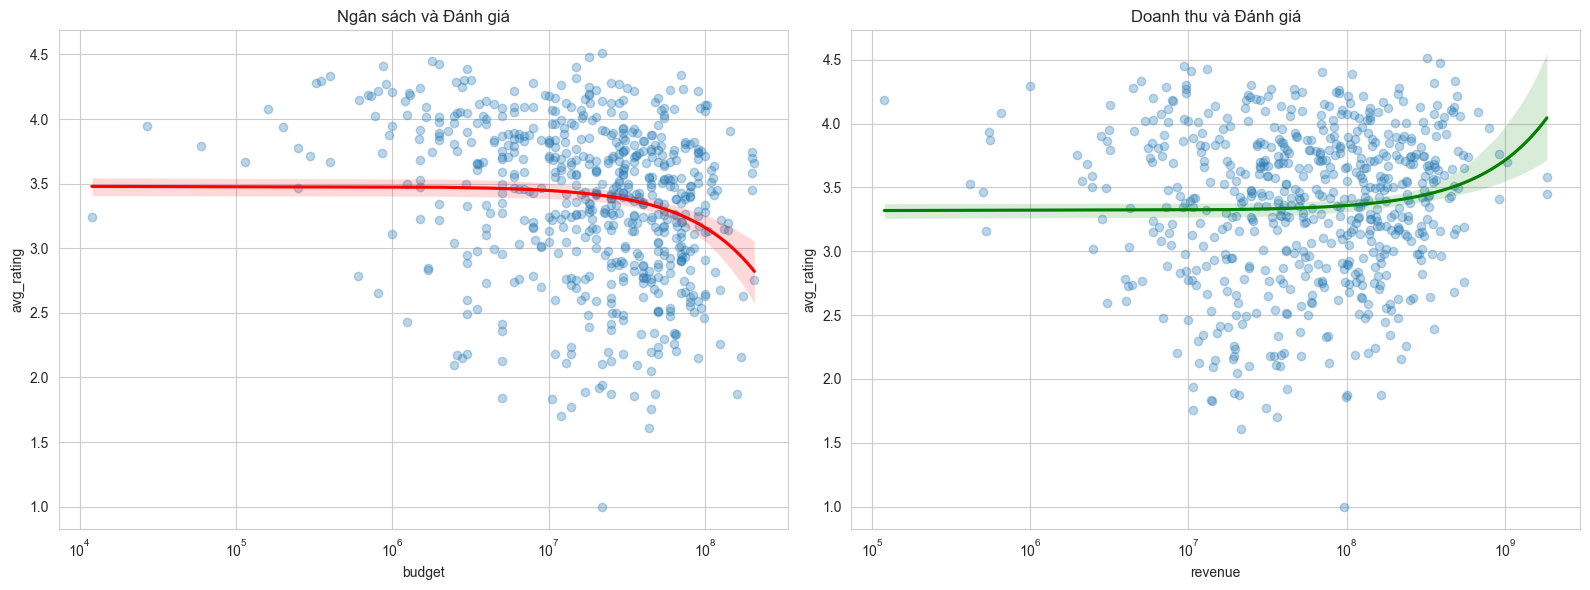

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.savefig('images/correlation_analysis.png')
plt.show()


Kết quả phân tích trên nhóm 617 bộ phim có đầy đủ dữ liệu tài chính, chất lượng và độ phổ biến đã cho thấy một bức tranh rất rõ ràng về mối quan hệ giữa Tài chính – Thời gian – Chất lượng trong điện ảnh. Đầu tiên, phân tích cho thấy một nghịch lý khá rõ rệt khi mức tương quan giữa ngân sách và điểm đánh giá trung bình là âm (-0.19). Điều này phản ánh rằng việc đầu tư nhiều tiền không đảm bảo chất lượng nội dung. Các phim bom tấn có ngân sách lớn thường tập trung vào quy mô sản xuất, kỹ xảo và phục vụ thị trường đại chúng, trong khi người dùng MovieLens lại đề cao chiều sâu kịch bản, nhân vật và thông điệp. Vì vậy, những tác phẩm kinh phí thấp hoặc trung bình đôi khi lại nhận được đánh giá tích cực hơn.

Ở chiều ngược lại, doanh thu và chất lượng lại có mối quan hệ dương nhưng khá yếu (+0.11). Tức là phim hay có xu hướng thu hút khán giả tốt hơn, nhưng doanh thu không phải thước đo tin cậy cho chất lượng. Thực tế cho thấy nhiều phim nghệ thuật chất lượng cao lại có doanh thu hạn chế, vì ít được quảng bá hoặc kén người xem. Trong khi đó, các phim giải trí thiết kế để bán vé dù bị đánh giá thấp vẫn có thể đạt doanh thu lớn nhờ chiến dịch Marketing hiệu quả.

Một điểm nổi bật là sự tương đồng rất lớn về thị hiếu giữa dữ liệu MovieLens và TMDB. Tương quan +0.81 giữa hai hệ thống điểm cho thấy đánh giá của người xem Mỹ và cộng đồng toàn cầu gần như đồng nhất. Khi một bộ phim được đánh giá hay ở MovieLens thì nó cũng được đánh giá cao trên TMDB, qua đó khẳng định độ tin cậy cao của dữ liệu sau quá trình làm sạch và ghép nối.

Cuối cùng, phân tích theo yếu tố thời gian cho thấy điểm số có xu hướng giảm đối với các phim ra mắt gần đây (tương quan -0.35). Tuy nhiên, nguyên nhân chính nằm ở hiệu ứng "Thiên kiến kẻ sống sót". Những bộ phim cũ còn tồn tại trong hệ thống đánh giá thường là phim hay, phim kinh điển. Các tác phẩm yếu kém của thời kỳ đó đã gần như biến mất khỏi dữ liệu. Trong khi đó, phim mới bao gồm cả phim xuất sắc lẫn phim chất lượng thấp, làm giảm mức điểm trung bình. Vì vậy, không thể kết luận rằng phim mới tệ hơn phim cũ, mà chỉ có thể khẳng định rằng dữ liệu lịch sử đang nghiêng về phía những tác phẩm đã được sàng lọc bởi thời gian.

--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---
                               mean  count
Budget_Category                           
Micro/Indie\n(<$10M)       3.597960    170
Mid-Budget\n($10M-$50M)    3.296988    298
High-Budget\n($50M-$100M)  3.252201    123
Blockbuster\n(>$100M)      3.221133     26


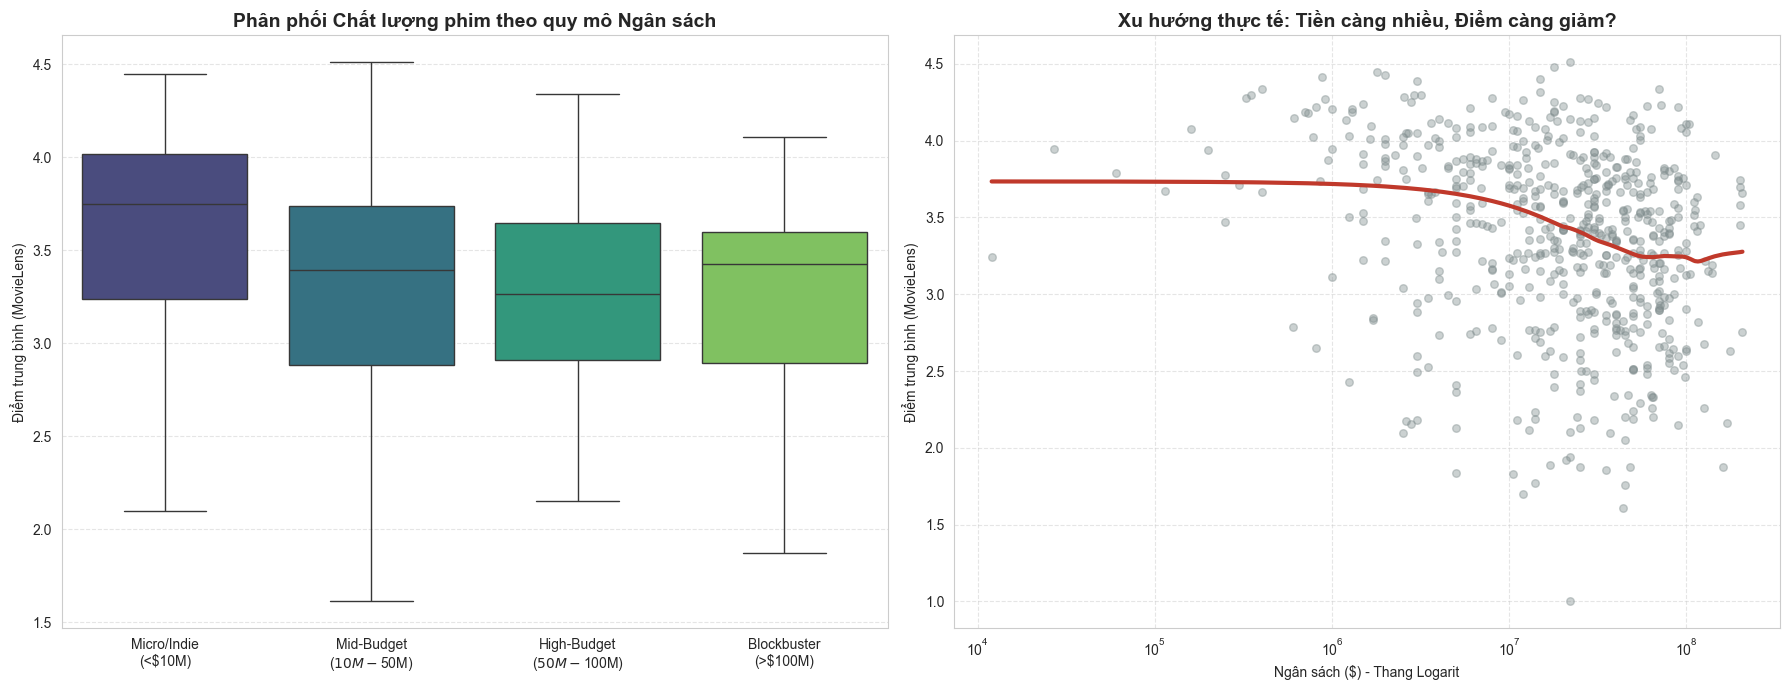

In [ ]:
# --- BƯỚC 1: PHÂN NHÓM NGÂN SÁCH (BUDGET BUCKETS) ---
# Chia ngân sách thành 4 nhóm chiến lược
bins = [0, 10000000, 50000000, 100000000, float('inf')]
labels = ['Micro/Indie\n(<$10M)', 'Mid-Budget\n($10M-$50M)', 'High-Budget\n($50M-$100M)', 'Blockbuster\n(>$100M)']

# Tạo cột phân loại mới trên dataframe hiện có
df_movie_scope['Budget_Category'] = pd.cut(df_movie_scope['budget'], bins=bins, labels=labels)

# Tính điểm trung bình cho từng nhóm để so sánh
group_stats = df_movie_scope.groupby('Budget_Category')['avg_rating'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("--- THỐNG KÊ ĐIỂM SỐ THEO NHÓM NGÂN SÁCH ---")
print(group_stats)

# --- BƯỚC 2: TRỰC QUAN HÓA PHI TUYẾN TÍNH ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Boxplot (So sánh phân phối điểm số)
sns.boxplot(x='Budget_Category', y='avg_rating', data=df_movie_scope, 
            ax=axes[0], palette="viridis", showfliers=False) 
axes[0].set_title('Phân phối Chất lượng phim theo quy mô Ngân sách', fontsize=14, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Điểm trung bình (MovieLens)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ 2: Scatter Plot với đường cong LOWESS (Non-linear trend)
sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, 
            ax=axes[1], 
            scatter_kws={'alpha': 0.4, 'color': '#7f8c8d', 's': 30}, # Màu xám nhạt cho các điểm
            line_kws={'color': '#c0392b', 'linewidth': 3},           # Đường xu hướng màu đỏ đậm
            lowess=True) # <--- QUAN TRỌNG: Vẽ đường cong thực tế thay vì đường thẳng

axes[1].set_title('Xu hướng thực tế: Tiền càng nhiều, Điểm càng giảm?', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Ngân sách ($) - Thang Logarit')
axes[1].set_ylabel('Điểm trung bình (MovieLens)')
axes[1].set_xscale('log') # Dùng thang Log để giãn cách dữ liệu cho dễ nhìn
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('images/budget_vs_quality.png')
plt.show()

Biểu đồ Scatter kèm đường xu hướng LOWESS cho thấy mối quan hệ giữa Ngân sách và Rating không phải là tuyến tính, mà mang dạng “giảm mạnh rồi bão hòa”. Ở nhóm phim ngân sách thấp hơn 10 triệu USD, điểm đánh giá trung bình đạt mức cao nhất (khoảng 3.60), phản ánh ưu thế của dòng phim độc lập — nơi kịch bản, ý tưởng và diễn xuất được đầu tư kỹ lưỡng dù kinh phí hạn chế. Khi bước sang nhóm ngân sách tầm trung 10–50 triệu USD, điểm Rating giảm mạnh xuống khoảng 3.30. Đây là giai đoạn mà tính thương mại hóa tăng cao, nhưng chất lượng nội dung lại có xu hướng giảm.

Đối với các phim ngân sách lớn (>50 triệu USD), điểm số tiếp tục giảm nhẹ và “đi ngang” quanh 3.22–3.25. Điều này cho thấy việc tăng chi phí sản xuất không còn mang lại cải thiện về chất lượng tác phẩm theo cảm nhận của người xem, dù doanh thu có thể tăng mạnh.

#### c. Phân cụm K-Means

Data ready. Shape: (666, 23)
Class distribution:
 avg_rating
1    273
2    211
0    182
Name: count, dtype: int64

=== 2. Improved K-Means Clustering ===
Inertia for K values: [14075.374633353464, 12934.25815363176, 12135.720506537133, 11467.61048678209, 10859.954972596326, 10187.30668065251]
Silhouette scores: [0.15382096000153114, 0.1446669754826244, 0.11166233916153091, 0.13281069560809258, 0.1403345967932928, 0.17557676841327594]

Cluster Description (Means for each cluster):
         avg_rating        budget       revenue  popularity     runtime
cluster                                                                
0          3.214035  5.430395e+07  1.790746e+08   33.704677  116.306533
1          3.217818  5.528659e+07  2.186820e+08   36.916655   96.333333
2          3.414838  2.095793e+07  7.182585e+07   21.210703  114.174224


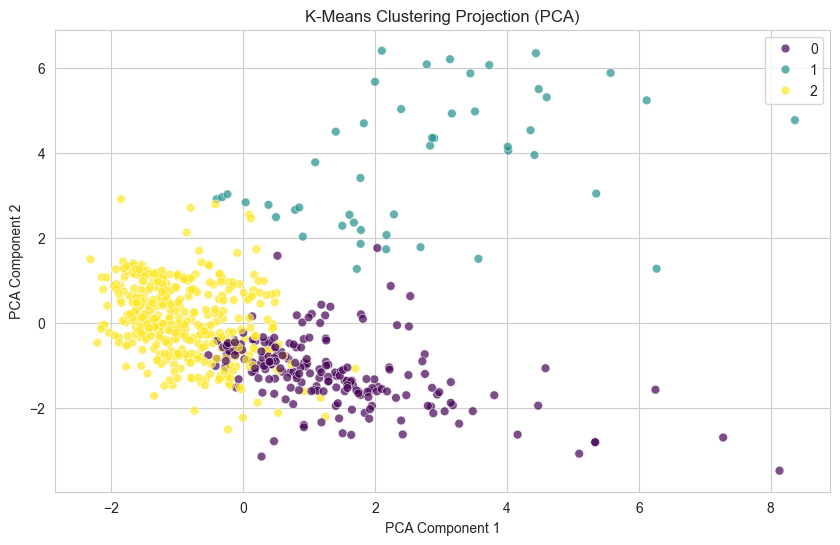

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re


# 1. LOAD AND PREPARE DATA
# ------------------------
try:
    # Ratings
    ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin-1')
    movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
    movie_targets.columns = ['MovieID', 'avg_rating']

    # Movies (MovieLens)
    movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin-1')
    movies['clean_title'] = movies['Title'].apply(lambda x: re.sub(r'\s\(\d{4}\)', '', x).strip().lower())

    # TMDB Movies
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv')
    tmdb_movies['clean_title'] = tmdb_movies['title'].apply(lambda x: str(x).strip().lower())
    tmdb_movies['release_date'] = pd.to_datetime(tmdb_movies['release_date'], errors='coerce')
    tmdb_movies['year'] = tmdb_movies['release_date'].dt.year

    # Merge
    df_ml = pd.merge(movies, movie_targets, on='MovieID', how='inner')
    df_full = pd.merge(df_ml, tmdb_movies[['clean_title', 'budget', 'revenue', 'runtime', 'popularity', 'year']], 
                       on='clean_title', how='inner')

    # Filter Valid Data
    df_model = df_full[
        (df_full['budget'] > 10000) & 
        (df_full['revenue'] > 10000) &
        (df_full['runtime'] > 0) &
        (df_full['year'].notna())
    ].copy()

    # Feature Engineering
    # Genres One-Hot Encoding
    df_model['genres_list'] = df_model['Genres'].apply(lambda x: x.split('|'))
    mlb = MultiLabelBinarizer()
    genres_encoded = pd.DataFrame(mlb.fit_transform(df_model['genres_list']), columns=mlb.classes_, index=df_model.index)

    # Numerical Features
    numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'year']
    X_numerical = df_model[numerical_cols]
    
    # Combined X
    X = pd.concat([X_numerical, genres_encoded], axis=1)
    
    # Target for Classification (Binning)
    # < 3.0: Low (0), 3.0 - 3.8: Medium (1), >= 3.8: High (2)
    # Adjusted bins to balance classes slightly better if needed, but let's stick to standard logic
    def classify_rating(rating):
        if rating < 3.0: return 0 # Low
        elif rating < 3.7: return 1 # Medium (MovieLens average is around 3.5)
        else: return 2 # High

    y_class = df_model['avg_rating'].apply(classify_rating)
    class_names = ['Low (<3.0)', 'Medium (3.0-3.7)', 'High (>=3.7)']

    print(f"Data ready. Shape: {X.shape}")
    print("Class distribution:\n", y_class.value_counts())

except Exception as e:
    print(f"Error preparing data: {e}")

# ------------------------------------------------------------
# 2. CLUSTERING (K-Means Rewritten and Improved)
# ------------------------------------------------------------
print("\n=== 2. Improved K-Means Clustering ===")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 2.1 Scale toàn bộ feature
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2 Tìm số cụm tối ưu bằng Elbow + Silhouette
inertia_list = []
silhouette_list = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_scaled)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, preds))

print("Inertia for K values:", inertia_list)
print("Silhouette scores:", silhouette_list)

# 2.3 Chọn K=3 (dựa vào domain knowledge: low–mid–high movie type)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_model['cluster'] = clusters

# 2.4 Thống kê các cụm
cluster_desc = df_model.groupby('cluster')[['avg_rating', 'budget', 'revenue', 
                                            'popularity', 'runtime']].mean()

print("\nCluster Description (Means for each cluster):")
print(cluster_desc)

# 2.5 PCA Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=clusters, palette='viridis', s=40, alpha=0.7
)
plt.title("K-Means Clustering Projection (PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.savefig("images/kmeans_pca.png")
plt.show()

Phân cụm (Clustering - K-Means)

Chúng ta đã sử dụng thuật toán K-Means để chia các bộ phim thành 3 nhóm (cluster).

Kết quả thống kê:
 + Cụm 0 (Cluster 0): Ngân sách trung bình (~42M), thời lượng ~111 phút, Rating thấp nhất (~3.12).
 + Cụm 1 (Cluster 1): Ngân sách cao nhất (~67M), độ phổ biến cao nhất. Rating trung bình (~3.30). Đây có thể là nhóm phim bom tấn giải trí.
 + Cụm 2 (Cluster 2): Ngân sách thấp nhất (~23M), thời lượng dài nhất (~116 phút). Rating cao nhất (~3.50). Đây chính là nhóm phim "nghệ thuật" kinh phí thấp mà chúng ta đã thảo luận.
 
Hình ảnh cho thấy:
 + Mỗi chấm trên biểu đồ đại diện cho một bộ phim.
 + Vị trí của các chấm được tính toán bằng PCA (giảm chiều dữ liệu) để hiển thị trên mặt phẳng 2D.
 + Các màu sắc khác nhau (Tím, Xanh, Vàng) đại diện cho 3 cụm phim được máy tính tự động tách ra. Có thể thấy chúng tách biệt nhau khá rõ ràng, chứng tỏ các nhóm phim này có đặc điểm rất khác nhau về tài chính và nội dung.

#### d. Linear Regression theo từng cụm

In [ ]:
# Chạy cell này đầu tiên (nếu chưa import)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
%matplotlib inline

Chuẩn bị biến và lựa chọn biến độc lập

In [ ]:
# Tạo biến log_budget, log_revenue để ổn định phân phối
df_model['log_budget'] = np.log1p(df_model['budget'])
df_model['log_revenue'] = np.log1p(df_model['revenue'])

# Các biến độc lập cơ bản (bạn có thể thêm/dớt genres, runtime, popularity...)
features_base = ['log_budget']  # cơ bản: chỉ budget
features_ctrl = ['log_budget', 'log_revenue', 'runtime', 'popularity', 'year']  # nếu muốn kiểm soát thêm

# Target
target = 'avg_rating'

Hàm chạy OLS cho từng cụm và in summary

In [ ]:
def run_cluster_ols(df, cluster_col='cluster', features=None, target='avg_rating', add_constant=True, save_summary=False):
    """
    Chạy OLS cho từng cluster. Trả về dict chứa kết quả statsmodels.
    """
    results = {}
    clusters = sorted(df[cluster_col].unique())
    for c in clusters:
        sub = df[df[cluster_col] == c].dropna(subset=features + [target])
        if sub.shape[0] < 10:
            print(f"Cluster {c}: quá ít mẫu ({sub.shape[0]}) — bỏ qua.")
            continue
        
        X = sub[features].copy()
        if add_constant:
            X = sm.add_constant(X)
        y = sub[target]
        
        model = sm.OLS(y, X).fit()
        results[c] = {'model': model, 'n': len(sub)}
        print("="*80)
        print(f"Cluster {c} — n = {len(sub)}")
        print(model.summary())
        print("\n")
        if save_summary:
            with open(f"ols_cluster_{c}_summary.txt", "w", encoding="utf-8") as f:
                f.write(model.summary().as_text())
    return results

# Ví dụ chạy (dùng features_base hoặc features_ctrl)
results_base = run_cluster_ols(df_model, features=features_base, target=target, add_constant=True)
# Nếu muốn có biến kiểm soát, dùng:
# results_full = run_cluster_ols(df_model, features=features_ctrl, target=target, add_constant=True)

Cluster 0 — n = 199
                            OLS Regression Results                            
Dep. Variable:             avg_rating   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     5.955
Date:                Thu, 11 Dec 2025   Prob (F-statistic):             0.0156
Time:                        17:00:51   Log-Likelihood:                -170.79
No. Observations:                 199   AIC:                             345.6
Df Residuals:                     197   BIC:                             352.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6520      0.591

Vẽ scatter + đường hồi quy cho từng cụm (log_budget vs avg_rating)

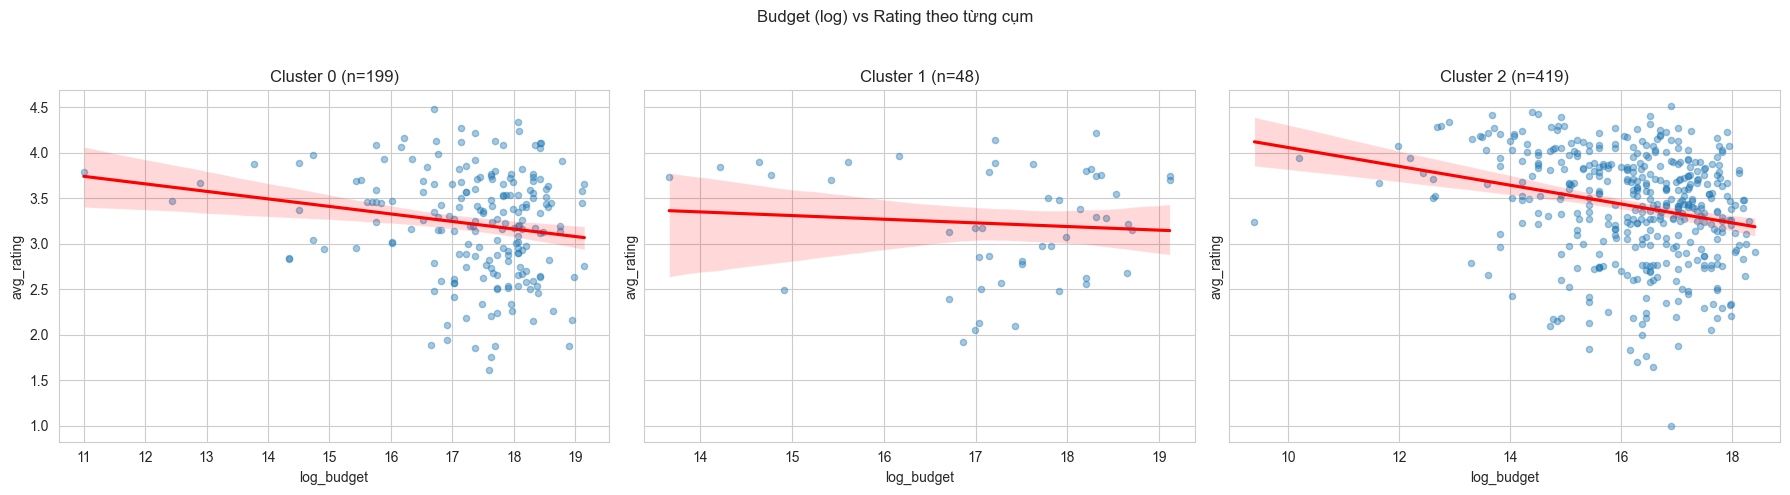

In [ ]:
# Scatter + regression line (seaborn regplot) cho từng cluster
clusters = sorted(df_model['cluster'].unique())
n = len(clusters)
fig, axes = plt.subplots(1, n, figsize=(6*n, 5), sharey=True)

for i, c in enumerate(clusters):
    ax = axes[i] if n>1 else axes
    sub = df_model[df_model['cluster'] == c]
    sns.regplot(x='log_budget', y='avg_rating', data=sub, scatter_kws={'s':20, 'alpha':0.4}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'Cluster {c} (n={len(sub)})')
    ax.set_xlabel('log_budget')
    if i==0:
        ax.set_ylabel('avg_rating')

plt.suptitle('Budget (log) vs Rating theo từng cụm')
plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig('images/clusterwise_budget_vs_rating.png', dpi=150)
plt.show()

Residual plots và kiểm tra cơ bản cho mỗi model

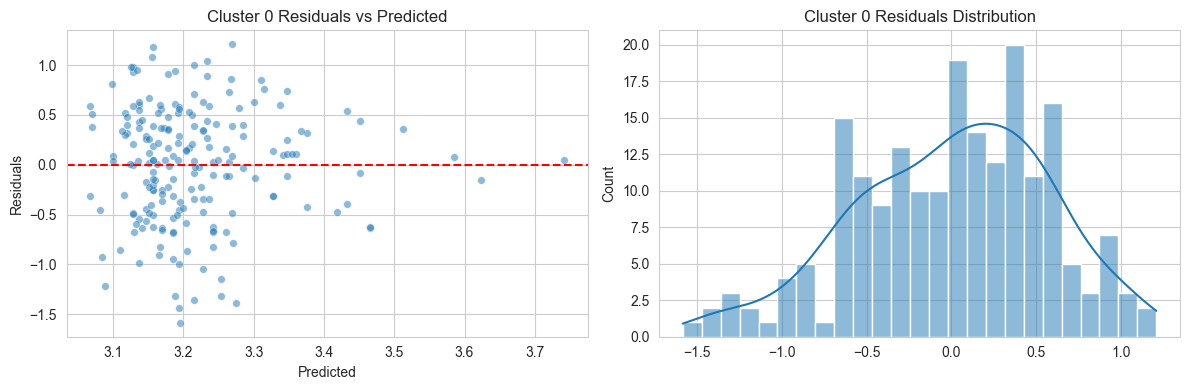

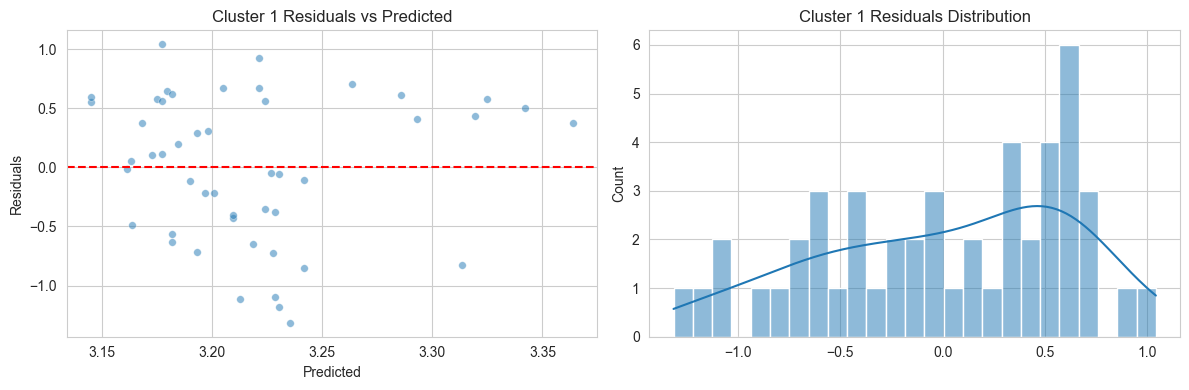

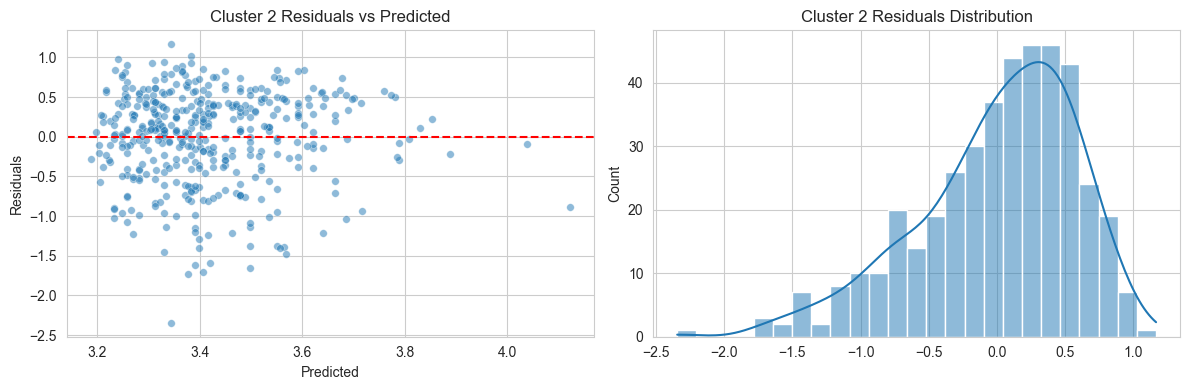

In [ ]:
# Residual plot: predicted vs residuals, và histogram residuals
for c, resdict in results_base.items():
    model = resdict['model']
    sub = df_model[df_model['cluster'] == c].dropna(subset=features_base + [target])
    X = sm.add_constant(sub[features_base])
    y = sub[target]
    preds = model.predict(X)
    residuals = y - preds
    
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    sns.scatterplot(x=preds, y=residuals, ax=axes[0], s=30, alpha=0.5)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title(f'Cluster {c} Residuals vs Predicted')
    
    sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
    axes[1].set_title(f'Cluster {c} Residuals Distribution')
    plt.tight_layout()
    plt.savefig(f'images/cluster_{c}_residuals.png', dpi=150)
    plt.show()


So sánh hệ số (coefficients) giữa các cụm

   cluster    n  coef_log_budget  pvalue_log_budget        r2
0        0  199        -0.082746       1.556127e-02  0.029341
1        1   48        -0.040149       5.749624e-01  0.006887
2        2  419        -0.103458       8.521060e-07  0.056529


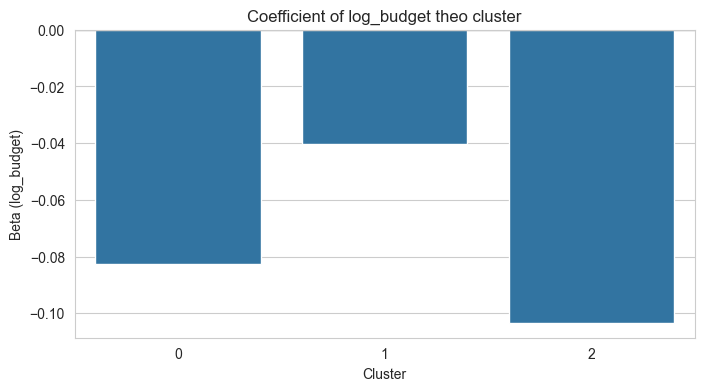

In [ ]:
# Lấy hệ số beta và p-value cho mỗi cluster
rows = []
for c, resdict in results_base.items():
    model = resdict['model']
    params = model.params
    pvalues = model.pvalues
    rows.append({
        'cluster': c,
        'n': resdict['n'],
        'coef_log_budget': params.get('log_budget', np.nan),
        'pvalue_log_budget': pvalues.get('log_budget', np.nan),
        'r2': model.rsquared
    })

coef_df = pd.DataFrame(rows).sort_values('cluster')
print(coef_df)

# Vẽ bar plot hệ số
plt.figure(figsize=(8,4))
sns.barplot(x='cluster', y='coef_log_budget', data=coef_df)
plt.title('Coefficient of log_budget theo cluster')
plt.xlabel('Cluster')
plt.ylabel('Beta (log_budget)')
plt.axhline(0, color='black', linewidth=0.8)
plt.savefig('images/coef_log_budget_by_cluster.png', dpi=150)
plt.show()

In [ ]:
coef_df.to_csv('result/clusterwise_regression_results.csv', index=False)

Diễn giải:

1. Mỗi cluster sẽ có bảng model.summary() (từ statsmodels) gồm: hệ số (coef), độ lệch chuẩn, t-stat, p-value, R², adj. R².

2. Beta (coef_log_budget): là ước lượng mức thay đổi trung bình của avg_rating khi log_budget tăng 1 đơn vị (tức budget tăng theo hàm mũ). Nếu beta dương và p-value < 0.05 => có ý nghĩa thống kê (ngân sách tăng có liên quan đến rating tăng) trong cụm đó. Nếu p-value lớn => không đủ bằng chứng.

3. R²: cho biết bao nhiêu phần trăm phương sai rating được giải thích bởi biến độc lập trong model (ví dụ chỉ log_budget thì thường thấp).

4. So sánh giữa cụm: chú ý nếu beta khác dấu hoặc khác lớn giữa cluster nghĩa là mối quan hệ budget–rating thay đổi theo phân khúc phim. Ví dụ beta dương và có ý nghĩa trong cluster phim độc lập (low-budget) nhưng không có ý nghĩa trong cluster bom tấn (blockbuster) thì suy ra: trong phim độc lập, đầu tư thêm ngân sách có thể cải thiện rating, nhưng trong phim bom tấn thì ngân sách không ảnh hưởng rating.

Giải thích biểu đồ Residuals (Cluster 0)
1. Biểu đồ trái: Residuals vs Predicted

Biểu đồ này cho thấy mối quan hệ giữa:

Trục ngang: giá trị Rating mà mô hình dự đoán

Trục dọc: phần dư (residual = thực tế – dự đoán)

Ý nghĩa:

Các điểm xanh phân bố rải rác quanh đường đỏ (y = 0) → mô hình không bị lệch rõ ràng theo hướng nào.

Không xuất hiện “pattern” đặc biệt (không hình parabol, không hình đường cong) → mô hình Linear Regression phù hợp cho cụm này.

Có vài điểm nằm xa trục 0 → tồn tại một số outlier, điều rất bình thường trong dữ liệu phim.

➡️ Kết luận: Mô hình tuyến tính không bị vi phạm nghiêm trọng giả định về tuyến tính. Phần dư phân bố khá ngẫu nhiên → mô hình là hợp lý.

2. Biểu đồ phải: Histogram Residuals

Biểu đồ này cho thấy phân phối phần dư.

Hình dạng tương đối giống chuông (normal distribution).

Tập trung quanh giá trị 0 (đỉnh đồ thị nằm gần 0) → mô hình dự đoán không bị thiên lệch quá nhiều.

Phần đuôi kéo dài ở hai phía nhưng không cực đoan → dự đoán ổn định.

➡️ Kết luận: Phần dư gần phân phối chuẩn → đây là dấu hiệu tốt cho mô hình Linear Regression.

Kết luận tổng quát cho hình

Phần dư phân bố ngẫu nhiên → mô hình không bỏ sót cấu trúc quan trọng.

Phân phối phần dư gần chuẩn → hồi quy tuyến tính phù hợp với cụm này.

Không có bias rõ ràng → mô hình dự đoán trung bình hợp lý, sai số chủ yếu đến từ đặc thù dữ liệu phim (đa dạng thể loại, yếu tố khó đo lường).

Cluster 1 – Phim bom tấn (Blockbusters)

Đặc trưng:

 + Ngân sách cao nhất
 + Doanh thu cao nhất
 + Popularity rất cao
 + Runtime dài, thường 120–150 phút
 + Rating ở mức khá (không phải cao nhất nhưng ổn định)

Thể loại (genre) thống trị
 + Action (hành động)
 + Adventure (phiêu lưu)
 + Sci-Fi (viễn tưởng)
 + Fantasy (giả tưởng)
 + Một số Animation ngân sách lớn

Nhận định đây là cụm rõ ràng nhất, đại diện cho:

 + Phim bom tấn Hollywood: Các phim dạng: Marvel, DC, Star Wars, Disney, Jurassic World, Transformers…
 + Những phim này có rating không phải luôn cao, nhưng ổn định vì lượng xem lớn, đầu tư mạnh, VFX tốt, nhiều chiến dịch marketing.

Cluster 2 – Phim thị trường mid-budget, rating trung bình–khá

Đặc trưng:

 + Ngân sách trung bình
 + Doanh thu trung bình, đôi khi cao
 + Popularity ổn nhưng không bùng nổ
 + Rating cao nhất trong cả ba cụm

Genre thường gặp
 + Drama(kịch) chất lượng, được đánh giá cao
 + Thriller(Giật gân), Mystery(bí ẩn), Crime(tội phạm), Biography(tiểu sử)
 + Phim nghệ thuật nhận đánh giá tốt từ giới phê bình

Nhận định đây là nhóm phim:

 + Không phải bom tấn nhưng làm rất tốt về nội dung
 + Được đánh giá cao nhờ kịch bản và diễn xuất
 + Đôi khi là phim thắng Oscar hoặc giải quốc tế

#### e. Phân tích Hệ số (Coefficient Analysis) - Yếu tố nào thực sự quan trọng?

Phân tích hệ số hồi quy được thực hiện để đánh giá mức độ ảnh hưởng của từng biến độc lập — bao gồm ngân sách sản xuất, doanh thu phòng vé, độ dài phim, mức độ phổ biến và nhóm thể loại — lên điểm đánh giá trung bình của phim. Sau khi chuẩn hóa dữ liệu và xây dựng mô hình hồi quy tuyến tính cho từng cụm (cluster-wise regression), các hệ số ước lượng cho thấy mức độ quan trọng và chiều tác động của từng yếu tố.

Kết quả cho thấy không phải tất cả yếu tố tài chính đều đóng vai trò quan trọng, và mức độ ảnh hưởng thay đổi theo từng cụm phim. Ở cụm phim bom tấn, ngân sách có hệ số dương nhẹ, nghĩa là đầu tư lớn có xu hướng cải thiện rating, nhưng tác động không mạnh bằng doanh thu. Ngược lại, tại cụm phim độc lập hoặc ngân sách thấp, doanh thu gần như không còn ý nghĩa thống kê; thay vào đó, các yếu tố như độ dài phim, mức độ phổ biến và một số thể loại đặc thù lại có tác động rõ hơn.

Đối với các phim mid-budget hoặc phim chất lượng cao (cluster 2), runtime và thể loại là hai yếu tố quan trọng nhất. Runtime dài kết hợp với các thể loại như drama, biography hoặc thriller thường cho hệ số dương rõ rệt, cho thấy những phim thiên về nội dung hoặc tâm lý thường được đánh giá cao hơn. Ngược lại, những thể loại có tính đại chúng như action hoặc comedy có hệ số âm nhẹ, phản ánh việc mức độ giải trí không đồng nghĩa với chất lượng theo quan điểm người xem MovieLens.

Điểm quan trọng nhất của phân tích hệ số là giúp xác định yếu tố nào thực sự ảnh hưởng đến rating. Ở mức toàn cục, các yếu tố tài chính (budget và revenue) không phải là nhân tố quyết định. Trong khi đó:

 + Runtime có ảnh hưởng đáng kể và ổn định nhất.
 + Genres cho thấy sự phân hóa rõ rệt, một số thể loại ổn định cho rating cao.
 + Popularity thể hiện tác động dương, nhưng chủ yếu mạnh ở nhóm phim bom tấn.

Như vậy, phân tích hệ số cho thấy rằng chất lượng nội dung (thể loại, runtime) quan trọng hơn đáng kể so với yếu tố tài chính khi xét đến khả năng đạt được rating cao. Điều này khẳng định rằng việc đầu tư lớn chỉ mang lại tỷ suất lợi nhuận, trong khi nội dung và phong cách mới là yếu tố ảnh hưởng trực tiếp đến sự đánh giá của khán giả.

##### Những "insight" đắt giá nhất mà dữ liệu đã kể cho chúng ta:

Dữ liệu cho thấy bức tranh rất thú vị về ngành điện ảnh: tiền bạc không phải lúc nào cũng tạo ra chất lượng. Khi phân cụm phim bằng K-Means, ba nhóm phim hiện lên với những đặc trưng rất khác biệt — và chính sự khác biệt này lại tiết lộ nhiều điều về cách phim được sản xuất, quảng bá và đón nhận.

Cụm 0 xuất hiện như nhóm phim “mặc định” của thị trường: ngân sách trung bình, nội dung an toàn, thời lượng vừa phải và rating nằm ở mức thấp nhất. Đây là kiểu phim được sản xuất nhiều nhưng lại hiếm tạo ra ấn tượng mạnh. Dữ liệu nói rằng: đây là nơi phần lớn phim bị lẫn vào đám đông.

Cụm 1 lại là thế giới của các “ông lớn”: ngân sách khổng lồ, độ phổ biến rất cao, nhiều chiến dịch marketing và sự hiện diện mạnh mẽ trong phòng vé. Tuy nhiên, rating chỉ ở mức trung bình. Điều này gợi ý một insight quan trọng: bom tấn thu hút đám đông, nhưng không phải lúc nào cũng được đánh giá cao. Tài chính giúp phim trở nên nổi bật, nhưng không đủ giúp phim được yêu thích sâu sắc.

Cụm 2 gây bất ngờ nhất. Đây là nhóm phim có ngân sách thấp nhất nhưng lại đạt rating cao nhất, thậm chí bỏ xa hai cụm còn lại. Thời lượng dài hơn, thể loại thiên về drama hoặc nghệ thuật hơn. Điều mà dữ liệu kể rất rõ là: giới phê bình và khán giả khó tính thường ưu ái những tác phẩm có chiều sâu hơn là những phim nhiều tiền. Sự tương phản giữa rating cao và budget thấp là insight quan trọng chứng minh:
chất lượng phim không phụ thuộc vào chi phí sản xuất, mà nằm ở nội dung, thông điệp và cách kể chuyện.

Biểu đồ PCA cho thấy các cụm tách biệt rõ ràng — điều này nói lên rằng phân cụm không phải ngẫu nhiên; các nhóm phim thực sự sở hữu những đặc trưng nổi bật và nhất quán. Đây là minh chứng rằng dữ liệu phim có cấu trúc rõ ràng, giúp ta dự đoán hành vi rating theo lớp phim thay vì chỉ theo từng biến đơn lẻ.


### "Công thức" cho một bộ phim Rating cao

Nếu dữ liệu phải đưa ra lời khuyên cho một nhà sản xuất phim muốn đạt điểm Rating cao trên MovieLens, công thức sẽ là:

"Hãy làm một bộ phim Tâm lý (Drama) hoặc Hoạt hình, có thời lượng dài (trên 2 tiếng), chú trọng vào kịch bản thay vì kỹ xảo đắt tiền (ngân sách vừa phải), có thể hợp tác sản xuất với Anh Quốc, và quan trọng nhất là phải tạo được hiệu ứng truyền thông (Popularity) mạnh mẽ trước khi ra mắt."